In [15]:
from pathlib import Path

import numpy as np
import pandas as pd
from config.paths import EXTRACTED_ROOT, LABELS_ROOT
from scipy.spatial.transform import Rotation as R

CONF_THRESH = 0.6  # min RHE confidence to trust a mu/nu label
LOW_THRESH = 0.7  # mu/nu at or below this counts as low traversability

pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 220)


excluded_missions = {"ICE-1"}  # ICE-1 has unreliable RHE labels


def mission_stats(d: Path, rhe_dir: Path) -> dict | None:
    """Per-mission summary row, or None if core labels are missing."""
    trav = np.load(rhe_dir / "rhe_trav_labels.npy")
    ts = np.load(rhe_dir / "rhe_timestamp.npy").astype(float)
    mu, nu = trav[:, 0], trav[:, 1]

    mu_c = np.load(rhe_dir / "rhe_mu_observability.npy")
    nu_c = np.load(rhe_dir / "rhe_nu_observability.npy")
    conf_mu, conf_nu = mu_c >= CONF_THRESH, nu_c >= CONF_THRESH

    v = np.full(len(ts), np.nan)
    odom = np.load(d / "dlio_odom.npy")
    t_odom = odom[:, 0].astype(float)
    x = odom[:, 1]
    y = odom[:, 2]
    yaw = R.from_quat(odom[:, 4:8]).as_euler("zyx")[:, 0]
    vx, vy = np.gradient(x, t_odom), np.gradient(y, t_odom)
    v_odom = vx * np.cos(yaw) + vy * np.sin(yaw)
    v = np.interp(ts, t_odom, v_odom, left=np.nan, right=np.nan)

    return {
        "env": d.name.split("-")[0],
        "N": len(mu),
        "img": (d / "image_manifest.npz").exists(),
        "depth": (d / "depth_manifest.npz").exists(),
        "dur_min": (ts[-1] - ts[0]) / 60,
        "v_med": float(np.nanmedian(np.abs(v))),
        "stop_pct": 100 * float(np.mean(np.abs(v) < 0.1)),
        "muC_pct": 100 * float(conf_mu.mean()),
        "nuC_pct": 100 * float(conf_nu.mean()),
        "low_mu": int(((mu <= LOW_THRESH) & conf_mu).sum()),
        "low_nu": int(((nu <= LOW_THRESH) & conf_nu).sum()),
        "mu_med": float(np.median(mu)),
        "nu_med": float(np.median(nu)),
    }


def _stats_or_none(d: Path) -> dict | None:
    rhe_dir = LABELS_ROOT / d.name / "rhe"
    if not (rhe_dir / "rhe_trav_labels.npy").exists():
        return None
    return mission_stats(d, rhe_dir)


rows = {
    d.name: _stats_or_none(d)
    for d in sorted(EXTRACTED_ROOT.iterdir())
    if d.is_dir() and d.name not in excluded_missions
}
rows = {m: s for m, s in rows.items() if s is not None}

df = pd.DataFrame.from_dict(rows, orient="index")
df = df.sort_values(["env"], ascending=[True])
df.index.name = "mission"


print(f"{len(df)} missions")
print(
    f"CONF_THRESH: conf >= {CONF_THRESH},  LOW_THRESH: traversability <= {LOW_THRESH}"
)
print(
    f"totals: confident-low mu={df.low_mu.sum()} ({df.low_mu.sum() / df.N.sum() * 100:.1f}%), confident-low nu={df.low_nu.sum()} ({df.low_nu.sum() / df.N.sum() * 100:.1f}%)"
)
print(f"missions with images={int(df.img.sum())}")
df.round(2)

48 missions
CONF_THRESH: conf >= 0.6,  LOW_THRESH: traversability <= 0.7
totals: confident-low mu=7712 (4.4%), confident-low nu=3632 (2.1%)
missions with images=48


,env,N,img,depth,dur_min,v_med,stop_pct,muC_pct,nuC_pct,low_mu,low_nu,mu_med,nu_med
mission,,,,,,,,,,,,,
ALB-1,ALB,2405,True,True,4.01,0.44,17.26,86.61,44.53,188,50,0.83,0.83
ALB-2,ALB,4599,True,True,7.66,0.38,21.94,85.04,31.57,1180,432,0.81,0.80
ALB-3,ALB,1739,True,True,2.90,0.39,13.23,91.49,43.47,248,70,0.80,0.81
ARC-1,ARC,4009,True,True,6.68,0.61,11.80,92.14,46.77,294,44,0.91,0.91
ARC-2,ARC,3620,True,True,6.03,0.31,31.08,78.23,55.58,384,124,0.86,0.88
ARC-3,ARC,6340,True,True,10.56,0.41,21.62,85.71,55.90,582,242,0.89,0.87
ARC-4,ARC,3538,True,True,5.89,0.39,24.22,81.97,46.01,94,38,0.88,0.87
ARC-5,ARC,2770,True,True,4.61,0.62,10.47,91.26,44.77,60,44,0.91,0.92
ARC-6,ARC,2763,True,True,4.60,0.41,27.33,74.81,34.13,8,0,0.88,0.89


In [7]:
red_tint_missions = ["ARC-5", "ARC-6", "ARC-7", "SPX-3"]

# Display the dataframe only for the red-tint missions
df_red_tint = df[df.index.isin(red_tint_missions)]

# Only show mission, N, dur_min, stop_pct, low_mu, low_nu, mu_med, nu_med
df_red_tint = df_red_tint[
    ["env", "N", "dur_min", "stop_pct", "low_mu", "low_nu", "mu_med", "nu_med"]
]


print(df_red_tint.round(2))


         env     N  dur_min  stop_pct  low_mu  low_nu  mu_med  nu_med
mission                                                              
ARC-5    ARC  2770     4.61     10.47      50      18    0.91    0.92
ARC-6    ARC  2763     4.60     27.33       0       0    0.88    0.89
ARC-7    ARC  2973     4.95     16.55      62       8    0.89    0.90
SPX-3    SPX  1659     2.76     26.16       2       0    0.93    0.93


Choosing a train/valid split for the GrandTour traversability data.

Three constraints to satisfy (see findings):
1. **Terrain-aware** - no environment prefix (ETH, SBB, ALB, ...) may appear in both train and valid.
2. **Low-traversability coverage** - confident-low mu and nu must exist on *both* sides, or low-trav performance is untestable.
3. **Images required** - only missions with `image_manifest.npz` are trainable; balance/coverage only counts those.

Cell 1 prints the per-mission table. Use the env rollup and `evaluate_split` to test candidates.

### Environment rollup

In [8]:
# Environment-level rollup: a terrain-aware split must not let one env straddle train/valid.
env = (
    df
    .groupby("env")
    .agg(
        missions=("N", "size"),
        with_img=("img", "sum"),
        N=("N", "sum"),
        low_mu=("low_mu", "sum"),
        low_nu=("low_nu", "sum"),
        dur_min=("dur_min", "sum"),
    )
    .sort_values("low_mu", ascending=False)
)
env.round(1)

,missions,with_img,N,low_mu,low_nu,dur_min
env,,,,,,
ALB,3,3,8743,1160,252,14.6
ARC,7,7,26013,1000,256,43.3
KAEB,3,3,11645,478,280,19.4
EIG,2,2,7121,438,92,11.9
RIV,1,1,4708,436,58,7.8
LMB,2,2,6560,416,330,10.9
CON,4,4,18627,282,40,31.0
PIL,2,2,13532,156,48,22.5
SBB,2,2,6274,154,40,10.5


### Evaluate a candidate split

In [9]:
image_missions = df.index[df["img"]].tolist()
print("trainable missions (have images):", image_missions)


def evaluate_split(train: list[str], valid: list[str]) -> pd.DataFrame:
    """Summarise a candidate split and flag leakage / coverage problems."""
    train_env = {df.loc[m, "env"] for m in train if m in df.index}
    valid_env = {df.loc[m, "env"] for m in valid if m in df.index}

    def agg(ms):
        sub = df.loc[[m for m in ms if m in df.index]]
        img = sub[sub["img"]]
        return {
            "missions": len(sub),
            "with_img": int(sub["img"].sum()),
            "N_img": int(img["N"].sum()),
            "low_mu_img": int(img["low_mu"].sum()),
            "low_nu_img": int(img["low_nu"].sum()),
            "n_envs": sub["env"].nunique(),
        }

    out = pd.DataFrame({"train": agg(train), "valid": agg(valid)}).T

    print("mission overlap :", set(train) & set(valid) or "none")
    print("shared envs     :", train_env & valid_env or "none (terrain-aware OK)")
    for split in ("train", "valid"):
        if out.loc[split, "low_mu_img"] == 0:
            print(f"WARNING: {split} has no confident-low MU among image missions")
        if out.loc[split, "low_nu_img"] == 0:
            print(f"WARNING: {split} has no confident-low NU among image missions")
    return out


# Edit these once more missions have images extracted.
TRAIN = ["ETH-1"]
VALID = ["ETH-1"]
evaluate_split(TRAIN, VALID)

trainable missions (have images): ['ALB-1', 'ALB-2', 'ALB-3', 'ARC-1', 'ARC-2', 'ARC-3', 'ARC-4', 'ARC-5', 'ARC-6', 'ARC-7', 'CON-4', 'CON-3', 'CON-2', 'CON-1', 'CYN-1', 'CYN-2', 'EIG-1', 'EIG-2', 'ETH-1', 'ETH-2', 'ETH-3', 'GRI-1', 'HAUS-1', 'HEAP-1', 'HIL-1', 'HOEB-1', 'HOEB-2', 'KAEB-1', 'KAEB-2', 'KAEB-3', 'LEE-1', 'LEICA-1', 'LEICA-2', 'LMB-1', 'LMB-2', 'PIL-2', 'PIL-1', 'RIV-1', 'ROOT-1', 'SBB-1', 'SBB-2', 'SNOW-1', 'SNOW-2', 'SNOW-3', 'SPX-1', 'SPX-2', 'SPX-3', 'TRIM-1']
mission overlap : {'ETH-1'}
shared envs     : {'ETH'}


,missions,with_img,N_img,low_mu_img,low_nu_img,n_envs
train,1,1,2729,0,0,1
valid,1,1,2729,0,0,1


### Reading the table

- `low_mu` / `low_nu`: confident-low samples (`mu`/`nu` <= `LOW_THRESH` and confidence >= `CONF_THRESH`) - the scarce, safety-critical class.
- `muC_pct` / `nuC_pct`: fraction of timesteps with trustworthy mu / nu. Expect `nuC_pct` to be low (the robot rarely turns, so angular traversability is under-observed).
- `img`: trainable. Currently typically only ETH-1; the split only becomes meaningful once low-trav missions (LMB, ICE, ALB, ...) are extracted with images.

### Picking a split

Put whole environments on one side only, and make sure both sides keep some `low_mu`/`low_nu` mass. `evaluate_split` warns when a side has zero confident-low coverage or when an env leaks across the split.

### High-confidence mu/nu over time, per mission

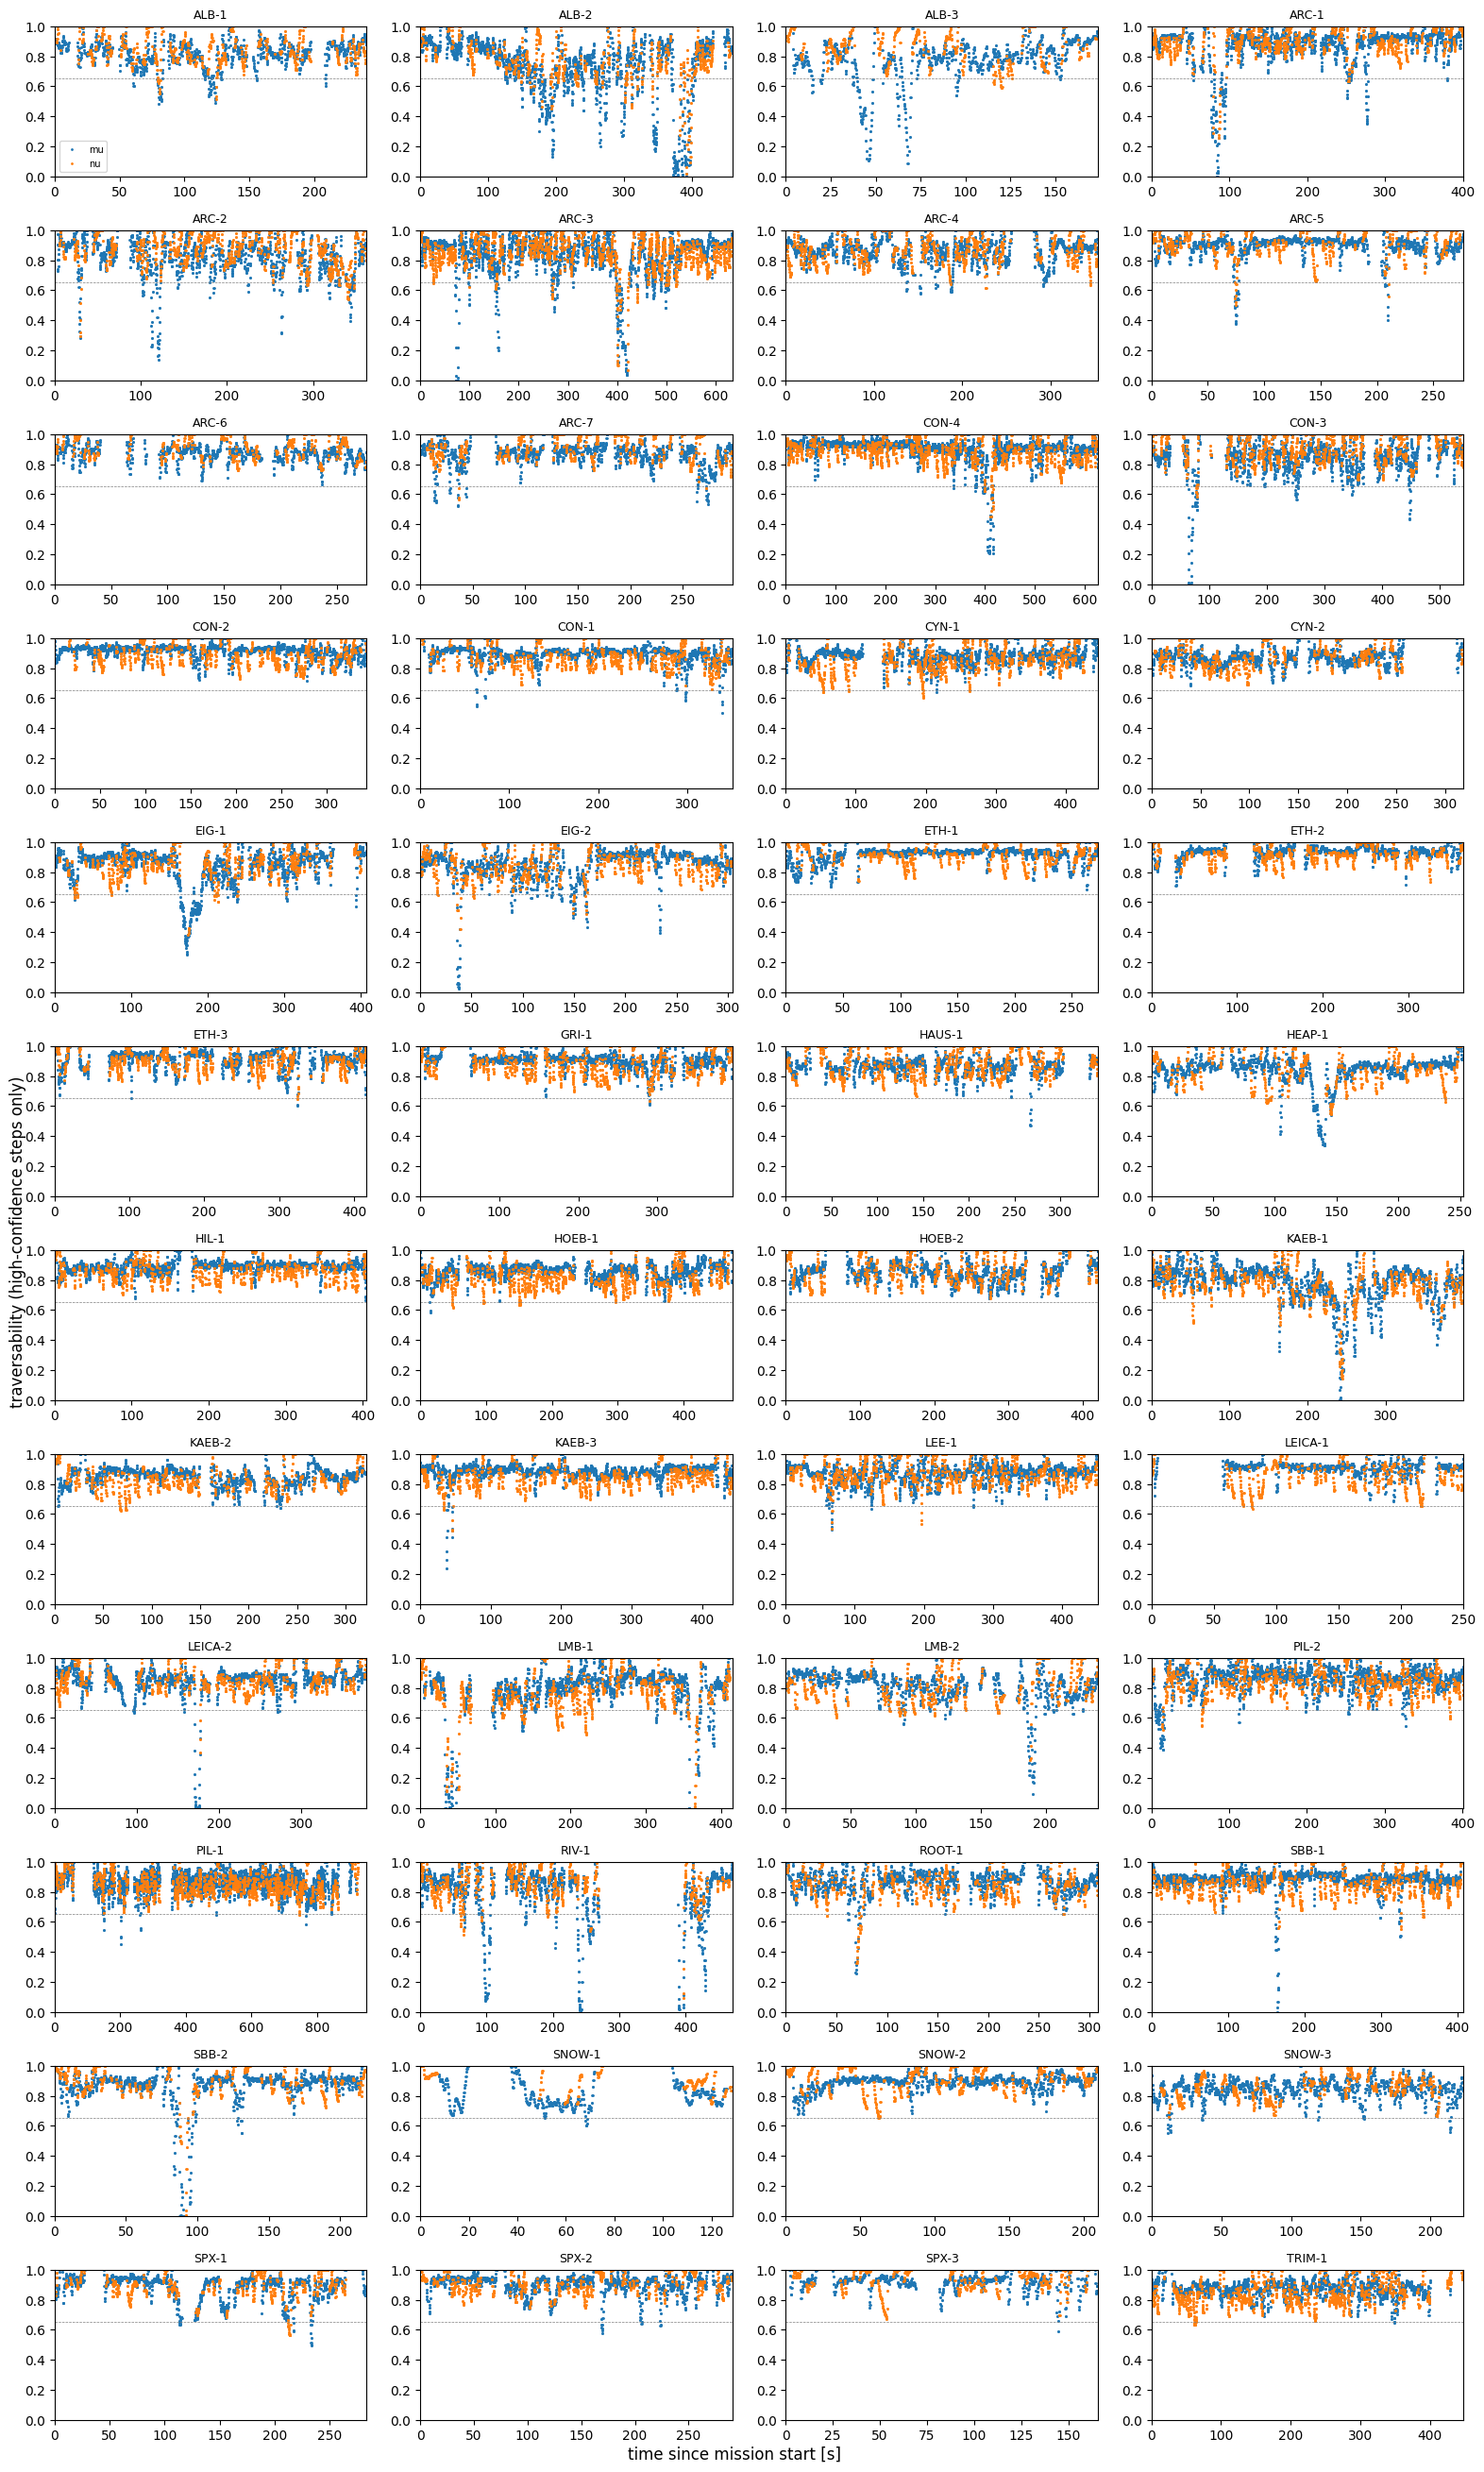

In [10]:
import matplotlib.pyplot as plt

# Per-mission mu/nu over time, masked to high-confidence steps only.
# Low-confidence steps are left blank; the x axis still spans the full mission.
missions = df.index.tolist()
ncols = 4
nrows = -(-len(missions) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.2 * nrows), squeeze=False)

for ax, m in zip(axes.flat, missions):
    d = LABELS_ROOT / m / "rhe"
    trav = np.load(d / "rhe_trav_labels.npy")
    t = np.load(d / "rhe_timestamp.npy").astype(float)
    t = t - t[0]
    mu_c = np.load(d / "rhe_mu_observability.npy")
    nu_c = np.load(d / "rhe_nu_observability.npy")

    mu = np.where(mu_c >= CONF_THRESH, trav[:, 0], np.nan)
    nu = np.where(nu_c >= CONF_THRESH, trav[:, 1], np.nan)
    ax.plot(t, mu, ".", ms=2, label="mu")
    ax.plot(t, nu, ".", ms=2, label="nu")
    ax.axhline(LOW_THRESH, color="grey", lw=0.5, ls="--")
    ax.set_xlim(0, t[-1])
    ax.set_ylim(0, 1)
    ax.set_title(m, fontsize=9)

for ax in axes.flat[len(missions) :]:
    ax.axis("off")
axes.flat[0].legend(loc="lower left", fontsize=7)
fig.supxlabel("time since mission start [s]")
fig.supylabel("traversability (high-confidence steps only)")
fig.tight_layout()
plt.show()